Loading weights: 100%|██████████| 206/206 [00:00<00:00, 12058.82it/s]


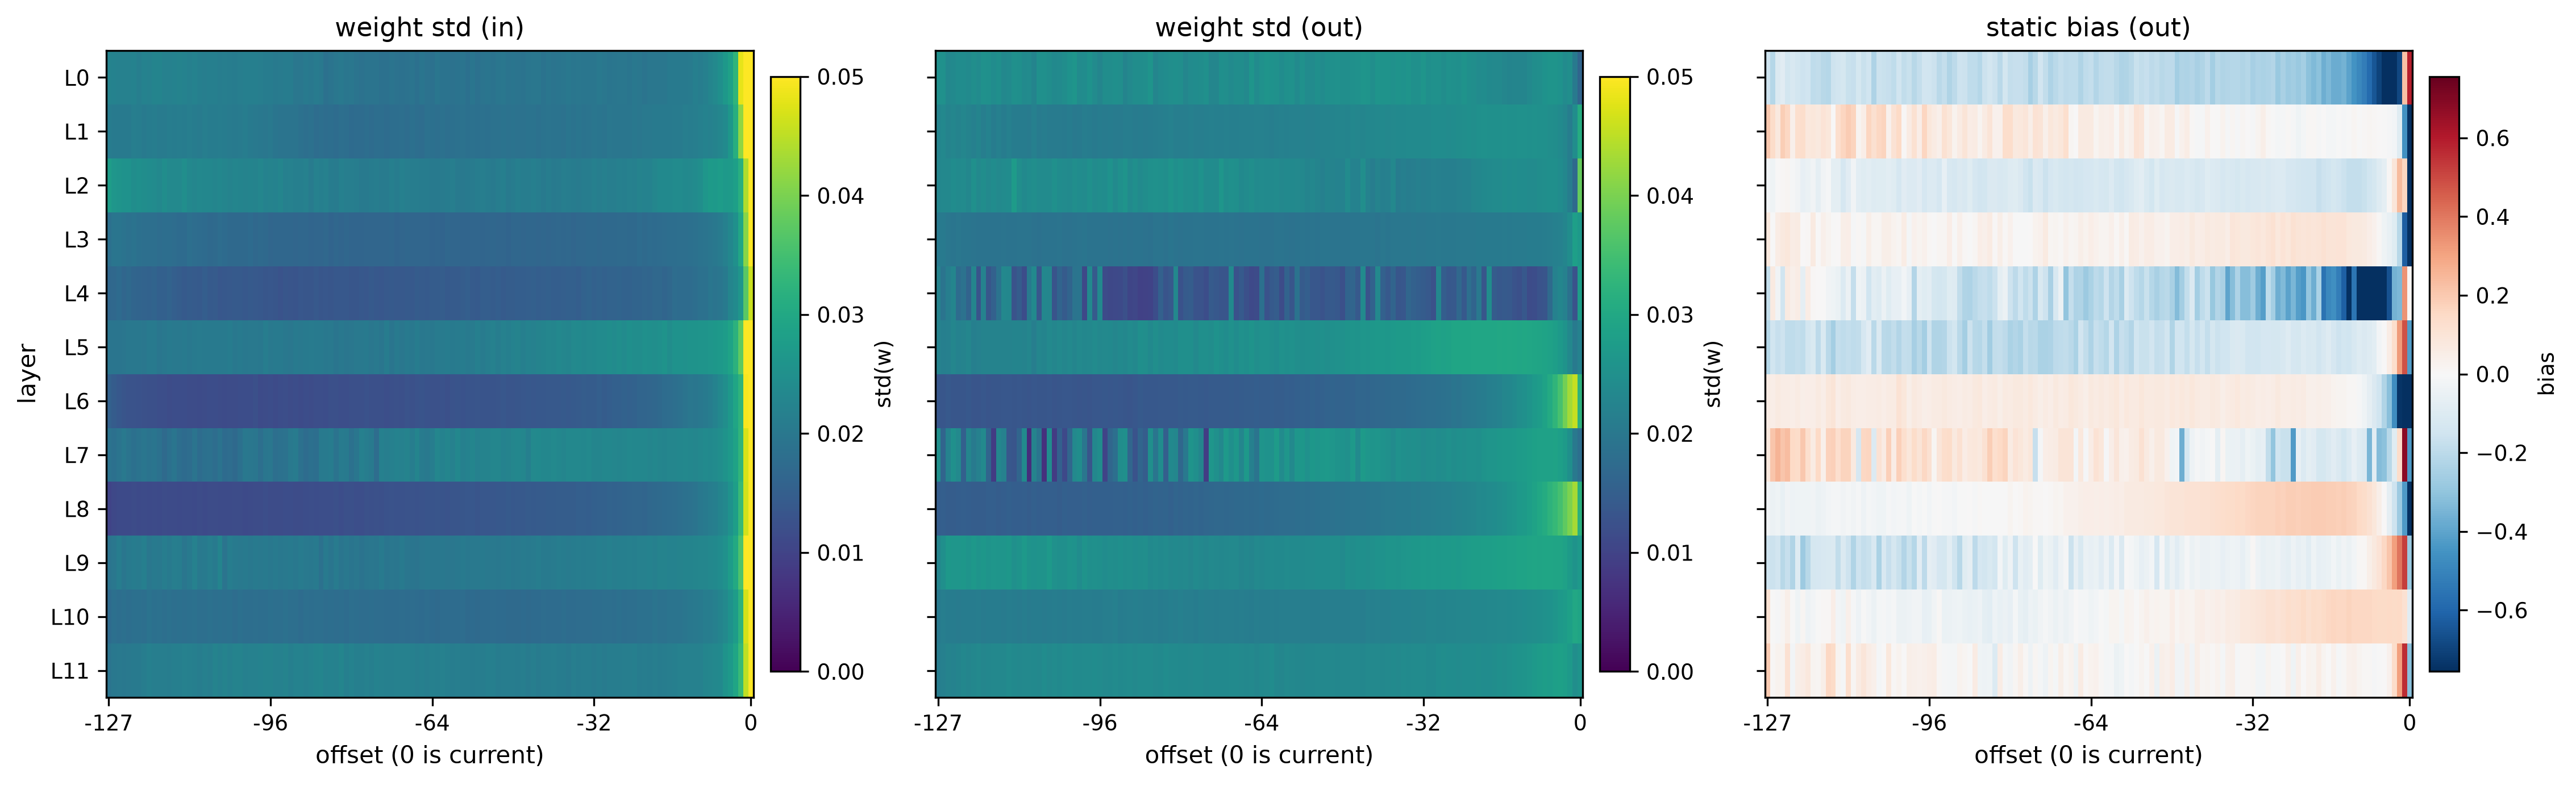

In [44]:
import os
import numpy as np
import torch
import matplotlib.pyplot as plt
from trainer_model import LanguageModel

torch.set_grad_enabled(False)
plt.rcParams.update({
    "figure.dpi": 300, "savefig.dpi": 300,
    "axes.titlesize": 11, "axes.labelsize": 10,
    "xtick.labelsize": 9, "ytick.labelsize": 9,
})

CMAP_STD = "viridis"
CMAP_MEAN = "RdBu_r"

CKPT_PATH = "results_pretrain/base_nope_w128d16r0h1g1_42"    # ← 改成你的路径
model = LanguageModel.from_pretrained(CKPT_PATH).eval()
attns = model.transformer.attns
n_layers = len(attns)

# ---------- 提取 ConvPE 核 ----------
def extract_kernel(cp):
    W, h, ki, g, ko = cp.window_size, cp.heads, cp.kernel_in, cp.groups, cp.kernel_out
    if cp.rank == 0:
        cw   = cp.conv.weight.view(h, W, ki, W)
        bias = cp.conv.bias.view(h, W)
    else:
        r  = cp.rank
        dw = cp.convd.weight.view(r, ki, W)
        uw = cp.convu.weight.view(g, ko, r)
        cw   = torch.einsum("gor,rcw->gocw", uw, dw)[0].view(h, W, ki, W)
        bias = cp.convu.bias.view(h, W)
    return cw.detach().float().cpu(), bias.detach().float().cpu()

kernels = [extract_kernel(a.convpe) for a in attns]
W = kernels[0][0].shape[1]

# ---------- 统计 ----------
IN_W_STD = np.zeros((n_layers, W))
OUT_W_STD = np.zeros((n_layers, W))
OUT_BIAS  = np.zeros((n_layers, W))

for i, (cw, b) in enumerate(kernels):
    IN_W_STD[i]  = cw.std(dim=(0, 1, 2)).numpy()
    OUT_W_STD[i] = cw.std(dim=(0, 2, 3)).numpy()
    OUT_BIAS[i]  = b.mean(dim=0).numpy()

# ---------- 画布：1×3 布局 ----------
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), constrained_layout=True)

xticks = [0, 32, 64, 96, 127]
xticklabels = [-127, -96, -64, -32, 0]

# 统一 std 的颜色上限为 0.05
vmax_std_fixed = 0.05
vmax_bias = np.percentile(np.abs(OUT_BIAS), 99)

configs = [
    # 第一张：std(in)
    (axes[0], IN_W_STD,            "weight std (in)",   CMAP_STD,  0, vmax_std_fixed, "std(w)", True),
    
    # 第二张：std(out)，隐藏 Y 轴标签
    (axes[1], OUT_W_STD[:, ::-1],  "weight std (out)",  CMAP_STD,  0, vmax_std_fixed, "std(w)", False),
    
    # 第三张：bias(out)，隐藏 Y 轴标签
    (axes[2], OUT_BIAS[:, ::-1],   "static bias (out)", CMAP_MEAN, -vmax_bias, vmax_bias, "bias", False),
]

for ax, mat, title, cmap, vmin, vmax, cbl, show_ylabel in configs:
    im = ax.imshow(mat, aspect="auto", cmap=cmap, vmin=vmin, vmax=vmax,
                   origin="upper", interpolation="nearest")
    ax.set_title(title)
    
    # 处理 Y 轴
    ax.set_yticks(range(n_layers))
    if show_ylabel:
        ax.set_ylabel("layer")
        ax.set_yticklabels([f"L{i}" for i in range(n_layers)])
    else:
        ax.set_yticklabels([])  # 隐藏后两张图的 Y 轴标签
        
    ax.set_xticks(xticks)
    ax.set_xticklabels(xticklabels)
    ax.set_xlabel("offset (0 is current)")
    
    cb = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.02)
    cb.set_label(cbl, fontsize=9)

plt.show()

In [45]:
import pandas as pd
import numpy as np

# 获取 n_layers 和 W
n_layers = len(kernels)
W = kernels[0][0].shape[1]

# 初始化矩阵
IN_W_STD  = np.zeros((n_layers, W))
OUT_W_STD = np.zeros((n_layers, W))
OUT_BIAS  = np.zeros((n_layers, W))

for i, (cw, b) in enumerate(kernels):
    # IN 维度：index 0 对应 -127，index 127 对应 0 (无需翻转)
    IN_W_STD[i] = cw.std(dim=(0, 1, 2)).numpy()
    
    # OUT 维度：index 0 对应 0，index 127 对应 -127 (需要翻转以对齐 -127 到 0)
    OUT_W_STD[i] = cw.std(dim=(0, 2, 3)).numpy()[::-1]
    OUT_BIAS[i]  = b.mean(dim=0).numpy()[::-1]

# 生成列名：从 -127 到 0
cols = [str(-W + 1 + i) for i in range(W)]

def print_table(mat, name):
    df = pd.DataFrame(mat, index=[f"L{i}" for i in range(n_layers)], columns=cols)
    print(f"\n{'='*50} {name} {'='*50}")
    # 为了表格不要太宽，保留 4 位小数
    print(df.to_string(float_format=lambda x: f"{x:.4f}"))

# 打印表格
print_table(IN_W_STD, "IN_STD (weight std of input)  [左 -127, 右 0]")
print_table(OUT_W_STD, "OUT_STD (weight std of output) [左 -127, 右 0]")
print_table(OUT_BIAS, "OUT_BIAS (static bias of output) [左 -127, 右 0]")


================================================== IN_STD (weight std of input)  [左 -127, 右 0] ==================================================
      -127   -126   -125   -124   -123   -122   -121   -120   -119   -118   -117   -116   -115   -114   -113   -112   -111   -110   -109   -108   -107   -106   -105   -104   -103   -102   -101   -100    -99    -98    -97    -96    -95    -94    -93    -92    -91    -90    -89    -88    -87    -86    -85    -84    -83    -82    -81    -80    -79    -78    -77    -76    -75    -74    -73    -72    -71    -70    -69    -68    -67    -66    -65    -64    -63    -62    -61    -60    -59    -58    -57    -56    -55    -54    -53    -52    -51    -50    -49    -48    -47    -46    -45    -44    -43    -42    -41    -40    -39    -38    -37    -36    -35    -34    -33    -32    -31    -30    -29    -28    -27    -26    -25    -24    -23    -22    -21    -20    -19    -18    -17    -16    -15    -14    -13    -12    -11    -10     -9     -8     -7   